# Lab 14-07 · Branch Prediction and Speculation

Companion to [chapter 14-07](../../chapters/14-07-branch-prediction-and-speculation.md). Programs run on the course's RV32I simulator; `bpred.py` records their control transfers and replays them through predictor models. Run the cells in order.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../14-06-lab').resolve()))
import bpred, make_program
LOOP = '    .text\n    .globl _start\n_start:\n    li t2, 100\n1:  li t1, {trip}\n2:  addi t1, t1, -1\n    bnez t1, 2b\n    addi t2, t2, -1\n    bnez t2, 1b\n    ebreak\n'

## Part 1 · Loops

**Predict first:** how many mispredictions per inner-loop execution for a 1-bit and a 2-bit predictor?

In [2]:
for trip in (10, 4):
    ev, n, _ = bpred.trace({'l.s': LOOP.format(trip=trip)})
    row = {d: bpred.simulate(ev, direction=d)['mispredicts'] for d in ('nt', 'btfn', '1bit', '2bit', 'gshare')}
    print(f'inner loop of {trip:2d}, run 100 times ({sum(e.kind == "br" for e in ev)} branches):', row)

# watch a 2-bit counter on the trip-4 inner branch for the first 3 outer iterations
ev, n, _ = bpred.trace({'l.s': LOOP.format(trip=4)})
inner_pc = min(e.pc for e in ev if e.kind == 'br')
t = bpred.TwoBit(1, init=1)
line = []
for e in [e for e in ev if e.pc == inner_pc][:12]:
    p = t.predict(0); line.append(f"{t.t[0]}{'T' if p else 'N'}/{'T' if e.taken else 'N'}{'' if p == e.taken else '!'}")
    t.update(0, e.taken)
print('counter, prediction / outcome (! = miss):', ' '.join(line))

inner loop of 10, run 100 times (1100 branches): {'nt': 999, 'btfn': 101, '1bit': 202, '2bit': 103, 'gshare': 118}
inner loop of  4, run 100 times (500 branches): {'nt': 399, 'btfn': 101, '1bit': 202, '2bit': 103, 'gshare': 12}
counter, prediction / outcome (! = miss): 1N/T! 2T/T 3T/T 3T/N! 2T/T 3T/T 3T/T 3T/N! 2T/T 3T/T 3T/T 3T/N!


## Part 2 · The lab program under different predictors

Cycles on the five-stage pipeline are $N + 4 + S + 2M$ with $N$ = 1924 and $S$ = 10 (14-06).

**Predict first:** which helps more, gshare or a return-address stack?

In [3]:
prog = Path('../14-06-lab/program.s').read_text()
data = {0x2000 + 4 * i + k: ((x & 0xFFFFFFFF) >> 8 * k) & 0xFF for i, x in enumerate(make_program.ARRAY) for k in range(4)}
ev, n, _ = bpred.trace({'p.s': prog}, data)
cfgs = {'none': dict(direction='none'), 'static NT + BTB': dict(direction='nt'), '1-bit + BTB': dict(direction='1bit'),
        '2-bit + BTB': dict(direction='2bit'), '2-bit + BTB + RAS': dict(direction='2bit', ras_depth=16),
        'gshare + BTB + RAS': dict(direction='gshare', ras_depth=16)}
for name, c in cfgs.items():
    m = bpred.simulate(ev, **c)['mispredicts']
    print(f'{name:20s} M = {m:3d}   cycles = {n + 4 + 10 + 2 * m}')

none                 M = 456   cycles = 2850
static NT + BTB      M = 207   cycles = 2352
1-bit + BTB          M = 185   cycles = 2308
2-bit + BTB          M = 205   cycles = 2348
2-bit + BTB + RAS    M =  93   cycles = 2124
gshare + BTB + RAS   M =  42   cycles = 2022


## Part 3 · A branch on random data, and removing it

In [4]:
HEAD = '    .text\n    .globl _start\n_start:\n    li   sp, 0x4000\n    li   a0, 0x2000\n    li   a1, 1000\n    li   a2, 128\n    call count\n    ebreak\n'
BR = 'count:\n    li   t0, 0\n    beqz a1, 3f\n1:  lw   t1, 0(a0)\n    ble  t1, a2, 2f\n    addi t0, t0, 1\n2:  addi a0, a0, 4\n    addi a1, a1, -1\n    bnez a1, 1b\n3:  mv   a0, t0\n    ret\n'
BL = 'count:\n    li   t0, 0\n    beqz a1, 3f\n1:  lw   t1, 0(a0)\n    addi a0, a0, 4\n    slt  t2, a2, t1\n    add  t0, t0, t2\n    addi a1, a1, -1\n    bnez a1, 1b\n3:  mv   a0, t0\n    ret\n'
def lcg(n, seed=12345):
    x, out = seed, []
    for _ in range(n):
        x = (1103515245 * x + 12345) % 2**31; out.append((x >> 16) % 256)
    return out
vals = lcg(1000)
for name, body, v in (('branchy, random', BR, vals), ('branchy, sorted', BR, sorted(vals)), ('branchless, random', BL, vals)):
    d = {0x2000 + 4 * i + k: (x >> 8 * k) & 0xFF for i, x in enumerate(v) for k in range(4)}
    ev, n, sim = bpred.trace({'c.s': HEAD + body}, d)
    m = bpred.simulate(ev, direction='2bit', ras_depth=16)['mispredicts']
    print(f'{name:20s} count = {sim.x[10]}, N = {n}, mispredictions = {m}')

branchy, random      count = 516, N = 5526, mispredictions = 504
branchy, sorted      count = 516, N = 5526, mispredictions = 6


branchless, random   count = 516, N = 6010, mispredictions = 3


## Part 4 · Aliasing

Shrink the direction table for the sorted count loop and count mispredictions.

{1: 520, 2: 520, 4: 520, 8: 6, 16: 6, 1024: 6}


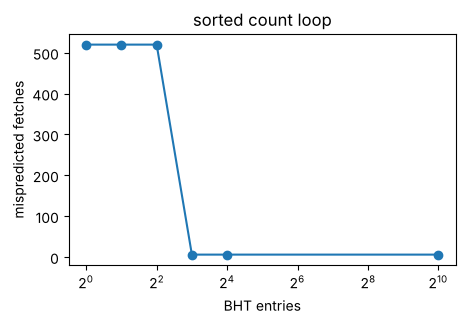

In [5]:
d = {0x2000 + 4 * i + k: (x >> 8 * k) & 0xFF for i, x in enumerate(sorted(vals)) for k in range(4)}
ev, n, _ = bpred.trace({'c.s': HEAD + BR}, d)
sizes = [1, 2, 4, 8, 16, 1024]
ms = [bpred.simulate(ev, direction='2bit', entries=e, ras_depth=16)['mispredicts'] for e in sizes]
print(dict(zip(sizes, ms)))
plt.figure(figsize=(5, 3)); plt.semilogx(sizes, ms, 'o-', base=2)
plt.xlabel('BHT entries'); plt.ylabel('mispredicted fetches'); plt.title('sorted count loop'); plt.show()